# 17 — Dual-pol vegetation indices: DpRVI, RVI and Stokes parameters

**Why not Pauli, Freeman–Durden or Yamaguchi?** These decompositions model the 3x3 matrix: they need
VV and the HH–VV phase (surface vs double-bounce), which a HH/HV acquisition does not measure.
Running them on dual-pol data would be wrong, not just approximate.

**Dual-pol alternatives used in the literature:**
* **DpRVI** = 1 − m·β (Mandal et al. 2020), m = degree of polarization, β = λ1/(λ1+λ2):
  0 for a pure scatterer (bare soil), towards 1 for random volume (dense vegetation).
* **RVI** = 4·σ_cross/(σ_co + σ_cross) (Trudel et al. 2012): intensity only, so it can be computed
  from GCOV as well (useful for the 11-date time series).
* **Stokes parameters** of the received wave (g0…g3), degree of polarization m and ellipticity χ.
  For linear transmit these describe the wave only; the m-χ *scattering* interpretation of
  compact-pol (circular transmit) does not apply.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # training/notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "17"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
import h5py
from nisar_s1 import polarimetry as pol
from nisar_s1.grid import polygon_mask
from nisar_s1.optical import Raster
from affine import Affine
import geopandas as gpd
session = P.load_session(kit["session_file"], required=("gslc_subsets", "c2_looks"))
looks = tuple(session["c2_looks"])

In [2]:
ind = {}
for i, (k, p) in enumerate(zip(["pre", "post"], session["gslc_subsets"][:2]), 1):
    with h5py.File(p) as h5:
        g = P.product_profile(h5).grids["frequencyA"]
        win = P.window_from_bounds(g, g.bounds)
        c = pol.c2_from_slc(P.read_layer(h5, g, "HH", win), P.read_layer(h5, g, "HV", win), looks)
    st = pol.stokes_dual(c)
    ind[k] = {"DpRVI": pol.dprvi(c), "RVI": pol.rvi_dual(c.c11, c.c22), "m": st["m"], "chi": st["chi"],
              "tr": win.transform @ Affine.scale(looks[1], looks[0]), "crs": win.crs}
    print(f"[{i}/2] {k} done")

[1/2] pre done
[2/2] post done


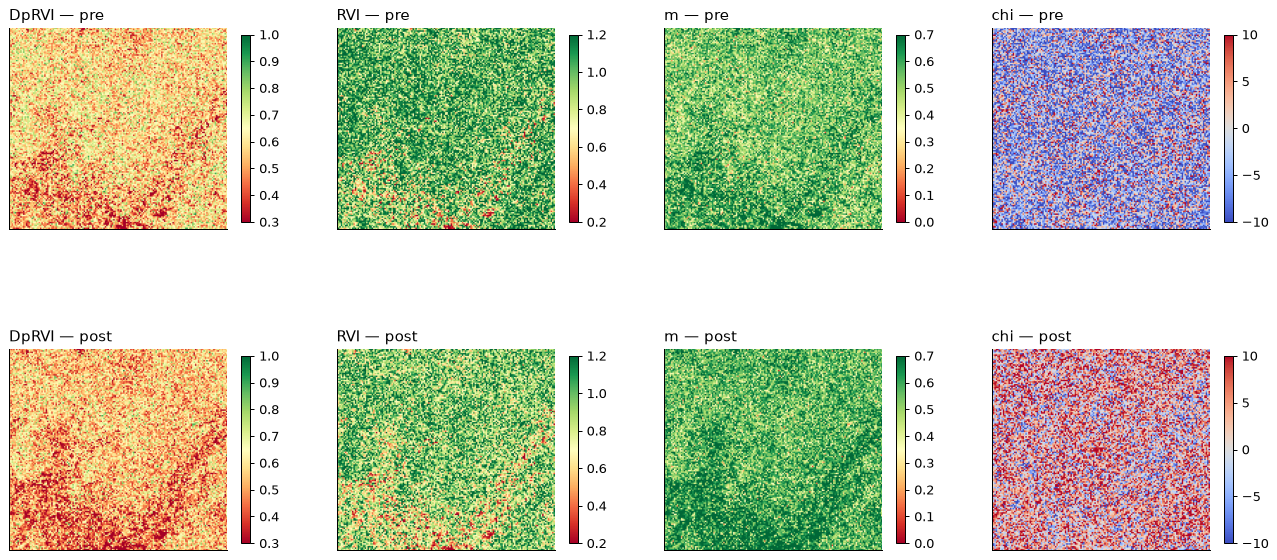

In [3]:
fig, axs = plt.subplots(2, 4, figsize=(18, 8.5))
for row, k in zip(axs, ind):
    for ax, (v, lim) in zip(row, [("DpRVI", (0.3, 1)), ("RVI", (0.2, 1.2)), ("m", (0, 0.7)), ("chi", (-10, 10))]):
        im = ax.imshow(ind[k][v], vmin=lim[0], vmax=lim[1], cmap="RdYlGn" if v != "chi" else "coolwarm")
        ax.set_title(f"{v} — {k}", loc="left"); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, shrink=0.7)
fig.savefig(OUT / "17_indices.png", dpi=100, bbox_inches="tight"); plt.show()

In [4]:
sites = gpd.read_file(kit["aoi"]["site_polygons"]).to_crs(ind["pre"]["crs"])
rows = []
for k, r in ind.items():
    ref = Raster(r["DpRVI"], r["tr"], r["crs"])
    for _, s in sites.iterrows():
        m = polygon_mask([s.geometry], ref) & np.isfinite(r["DpRVI"])
        rows.append({"date": k, "unit": s.role, **{v: float(np.nanmedian(r[v][m])) for v in ("DpRVI", "RVI", "m", "chi")}})
t = pd.DataFrame(rows).pivot(index="unit", columns="date")
t.round(3)

DpRVI           RVI             m           chi       
date      post    pre   post    pre   post    pre   post    pre
unit                                                           
control  0.569  0.589  0.958  1.007  0.555  0.536  3.716 -3.008
cut      0.498  0.528  0.813  0.902  0.620  0.593  8.183 -4.012

**Reading.** Forest has a high DpRVI and a low degree of polarization m (random volume). After the
cut, DpRVI of the cut decreases and m increases, but only by a few hundredths — the same message as
H/α in notebook 16: these normalized indices are built to be insensitive to the absolute power,
and the absolute HV power is precisely what the clear-cut changes most at L-band.

In [5]:
checks = {
    "DpRVI within [0, 1]": all(np.nanmax(r['DpRVI']) <= 1 + 1e-5 for r in ind.values()),
    "m within [0, 1]": all(np.nanmax(r['m']) <= 1 + 1e-5 for r in ind.values()),
    "DpRVI of the cut decreases": t.loc["cut", ("DpRVI", "post")] < t.loc["cut", ("DpRVI", "pre")],
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 17 STATUS: PASS")

  [x] DpRVI within [0, 1]
  [x] m within [0, 1]
  [x] DpRVI of the cut decreases
Module 17 STATUS: PASS
